# Wine Quality: separate datasets vs pooled vs pooled without `wine_type`

**Question:** how does having or not having a split of the data by wine type (red / white) affect the quality of a Support Vector Regressor (SVR) (regression of the `quality` score), and which chemical features are the most important according to permutation importance?

**Scenarios:**
1. `red` — model trained on red wine only
2. `white` — model trained on white wine only
3. `combined + wine_type` — pooled model, the wine-type feature is included
4. `combined, no wine_type` — pooled model without the wine-type feature

**Scheme:** load the cleaned data (`dataset/wine_clean.csv`, duplicates already removed) → baseline (constant = mean) → 5-fold CV (identical folds for all scenarios) → hold-out evaluation with `evaluate_classification_metrics` → permutation importance.

> The cleaned file is produced by `wine_quality_eda.ipynb`. Duplicates are removed there, **before** any train/test split; otherwise identical rows end up in both train and test (data leakage).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

numpy 2.5.1 | pandas 3.0.5 | sklearn 1.9.0


## Evaluation helper (provided)

In [3]:
def evaluate_classification_metrics(model, X_valid, y_valid, title="Classification Report"):
    """
    Universal function for evaluating models (including regressors)
    with classification metrics.
    """
    # 1. Make predictions
    predictions = model.predict(X_valid)

    # 2. If the model returns fractional numbers (regression), round them
    predictions_rounded = np.round(predictions)

    # 3. Compute the standard metrics
    # zero_division=0 prevents warnings if the model never predicted a given class
    acc = accuracy_score(y_valid, predictions_rounded)
    prec = precision_score(y_valid, predictions_rounded, average='macro', zero_division=0)
    rec = recall_score(y_valid, predictions_rounded, average='macro', zero_division=0)
    f1 = f1_score(y_valid, predictions_rounded, average='macro', zero_division=0)

    print(f"--- {title} ---")
    print(f"Accuracy:  {acc:.4f} (Share of exact hits)")
    print(f"Precision: {prec:.4f} (Macro)")
    print(f"Recall:    {rec:.4f} (Macro)")
    print(f"F1-Score:  {f1:.4f} (Macro)\n")

    # 4. Classification of the error size (our own metric)
    exact_matches = np.sum(predictions_rounded == y_valid)
    off_by_one = np.sum(np.abs(predictions_rounded - y_valid) == 1)
    total = len(y_valid)

    print("--- Error distribution ---")
    print(f"Exact match:            {exact_matches/total*100:.2f}%")
    print(f"Off by 1 point:         {off_by_one/total*100:.2f}%")
    print(f"Gross error (>1 point): {(total - exact_matches - off_by_one)/total*100:.2f}%\n")

    # 5. Confusion matrix visualisation
    cm = confusion_matrix(y_valid, predictions_rounded)

    # Get the unique classes (scores) that are actually present in the validation set
    classes = np.unique(np.concatenate([y_valid, predictions_rounded]))

    plt.figure(figsize=(8, 6))
    # annot=True shows the numbers, cmap='Blues' sets the blue colour map
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
                xticklabels=classes, yticklabels=classes)

    plt.title(f'Confusion Matrix: {title}')
    plt.ylabel('Actual score')
    plt.xlabel('Predicted score')
    plt.tight_layout()
    plt.show()

## 1. Loading the cleaned data

In [4]:
# The cleaned dataset is produced by wine_quality_eda.ipynb: duplicate rows are already removed
# (so identical rows cannot end up in both train and test) and there are no missing values.
CLEAN_PATH = "dataset/wine_clean.csv"

raw = pd.read_csv(CLEAN_PATH)

# Sanity checks: the experiment relies on these properties of the cleaned data
assert raw.isna().sum().sum() == 0, "unexpected missing values"
assert not raw.duplicated().any(), "unexpected duplicate rows"

# wine_type is stored as text in the CSV; the models need a number: 0 = red, 1 = white.
# quality_category (low / medium / high) is not used in this notebook, so it is dropped.
df = (raw.assign(wine_type=raw["wine_type"].map({"red": 0, "white": 1}))
         .drop(columns="quality_category"))
assert df["wine_type"].notna().all(), "unknown wine_type value"

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Combined dataset:", df.shape)
display(df["wine_type"].map({0: "red", 1: "white"}).value_counts().rename("rows").to_frame())

Missing values: 0
Duplicate rows: 0
Combined dataset: (5320, 13)


,rows
wine_type,
white,3961
red,1359


wine_type,red,white
quality,,
3,10,20
4,53,153
5,577,1175
6,535,1788
7,167,689
8,17,131
9,0,5


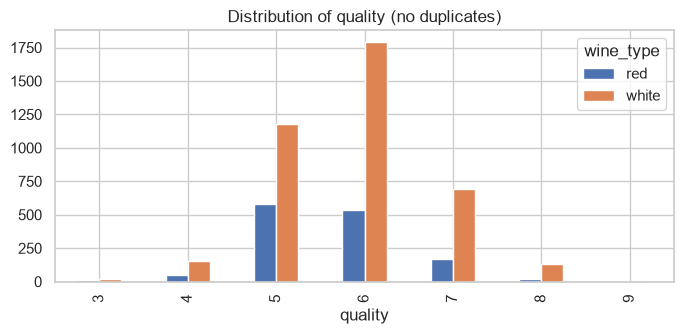

In [5]:
# Target distribution after cleaning
dist = pd.crosstab(df["quality"], df["wine_type"].map({0: "red", 1: "white"}))
display(dist)
dist.plot(kind="bar", figsize=(7, 3.5), title="Distribution of quality (no duplicates)")
plt.tight_layout(); plt.show()

## 2. Experiment setup

* Model: `GridSearchCV` tuning `SVR()` hyperparameters (like C and gamma).
* Baseline: `DummyRegressor(mean)`.
* All steps are in a `Pipeline`. **Unlike Random Forest, SVM algorithms are highly sensitive to unscaled features. Thus, a `StandardScaler` is included.**
* **Identical folds** for all scenarios: `StratifiedKFold` on the combination `wine_type + quality`. Therefore the predictions of every scenario can be compared row by row.
* Metrics: RMSE, MAE, R² (regression) + accuracy after rounding and the share of "±1 point" (as in the provided function).

**Fair comparison:** metrics on the `red` test set and on the `white` test set are different samples, so comparing the "red model" directly with the "combined model" on the whole test set would be incorrect. Therefore, for the pooled models we compute metrics separately on the red and white subsets.

In [6]:
FEATURES = [c for c in df.columns if c not in ("quality", "wine_type")]
FEATURES_WITH_TYPE = FEATURES + ["wine_type"]

def make_svr(cv_splits=3):
    # Pipeline гарантує, що StandardScaler тренується (fit)
    # виключно на тренувальних фолдах (нульовий витік даних)
    # і подає у SVR вже відмасштабовані дані
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR())
    ])
    
    param_grid = {
        'svr__C': [0.1, 1, 10],
        'svr__gamma': ['scale', 'auto', 0.1]
    }
    
    # Використовуємо стратифікований K-Fold для внутрішнього тюнінгу
    inner_cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=SEED)
    
    return GridSearchCV(
        pipeline, 
        param_grid, 
        cv=inner_cv, 
        scoring='neg_mean_squared_error', 
        n_jobs=-1
    )

def make_dummy():
    return Pipeline([("dummy", DummyRegressor(strategy="mean"))])

def reg_metrics(y_true, y_pred):
    r = np.round(y_pred)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, r),
        "Within±1": np.mean(np.abs(r - y_true) <= 1),
    }

## 3. Cross-validation (5-fold): out-of-fold predictions for every scenario
*(Note: Since we are using GridSearchCV inside the cross-validation loop, this is a Nested Cross-Validation and will take some time to run)*

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
strat = df["wine_type"].astype(str) + "_" + df["quality"].astype(str)
folds = list(skf.split(df, strat))

y = df["quality"].to_numpy()
is_red, is_white = (df["wine_type"] == 0).to_numpy(), (df["wine_type"] == 1).to_numpy()

scenarios = {
    "baseline (mean)":          dict(feats=FEATURES,           per_type=False, factory=make_dummy),
    "red only":                 dict(feats=FEATURES,           per_type=True,  factory=make_svr, only=0),
    "white only":               dict(feats=FEATURES,           per_type=True,  factory=make_svr, only=1),
    "combined + wine_type":     dict(feats=FEATURES_WITH_TYPE, per_type=False, factory=make_svr),
    "combined, no wine_type":   dict(feats=FEATURES,           per_type=False, factory=make_svr),
}

oof = {}   # out-of-fold predictions: name -> array of length len(df)
for name, cfg in scenarios.items():
    pred = np.full(len(df), np.nan)
    for tr, te in folds:
        if "only" in cfg:
            # Окремі моделі: тренуємо і валідуємо лише на відповідному типі вина
            tr = tr[df["wine_type"].to_numpy()[tr] == cfg["only"]]
            te = te[df["wine_type"].to_numpy()[te] == cfg["only"]]
            
        X_tr = df.iloc[tr][cfg["feats"]]
        y_tr = y[tr]
        X_te = df.iloc[te][cfg["feats"]]
        
        model = cfg["factory"]()
        
        if isinstance(model, GridSearchCV):
            # Перетворюємо генератор сплітів на список (list), щоб уникнути помилки pickling
            strat_tr = y_tr.astype(str)
            inner_cv = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_tr, strat_tr))
            model.cv = inner_cv
            model.fit(X_tr, y_tr)
        else:
            model.fit(X_tr, y_tr)
            
        pred[te] = model.predict(X_te)
    oof[name] = pred

print("Done")

Done


In [9]:
# Combine 'red only' + 'white only' into the "separate approach" (each wine is scored by the model of its own type)
oof["separate (red+white models)"] = np.where(is_red, oof["red only"], oof["white only"])

def table(mask, names):
    rows = {n: reg_metrics(y[mask], oof[n][mask]) for n in names}
    return pd.DataFrame(rows).T.round(4)

names_cmp = ["baseline (mean)", "separate (red+white models)", "combined + wine_type", "combined, no wine_type"]

print("=== All wines (red + white) ===")
res_all = table(np.ones(len(df), bool), names_cmp); display(res_all)
print("=== Red only ===")
res_red = table(is_red, names_cmp); display(res_red)
print("=== White only ===")
res_white = table(is_white, names_cmp); display(res_white)

=== All wines (red + white) ===


,RMSE,MAE,R2,Accuracy,Within±1
baseline (mean),0.8797,0.6947,-0.0000,0.4367,0.9269
separate (red+white models),0.6960,0.5268,0.3740,0.5731,0.9594
combined + wine_type,0.6912,0.5252,0.3826,0.5716,0.9600
"combined, no wine_type",0.6939,0.5266,0.3778,0.5705,0.9611


=== Red only ===


,RMSE,MAE,R2,Accuracy,Within±1
baseline (mean),0.8411,0.6844,-0.0439,0.3937,0.9411
separate (red+white models),0.6601,0.4934,0.3570,0.5990,0.9625
combined + wine_type,0.6477,0.4853,0.3810,0.6034,0.9669
"combined, no wine_type",0.6498,0.4876,0.3770,0.5990,0.9662


=== White only ===


,RMSE,MAE,R2,Accuracy,Within±1
baseline (mean),0.8925,0.6982,-0.0044,0.4514,0.9220
separate (red+white models),0.7079,0.5382,0.3681,0.5643,0.9583
combined + wine_type,0.7055,0.5389,0.3724,0.5607,0.9576
"combined, no wine_type",0.7084,0.5400,0.3673,0.5607,0.9594


In [10]:
# The same, but "a separate model on its own dataset" in the form it is usually compared (metrics on its own test data)
own = pd.DataFrame({
    "red model → red":     reg_metrics(y[is_red],   oof["red only"][is_red]),
    "white model → white": reg_metrics(y[is_white], oof["white only"][is_white]),
}).T.round(4)
display(own)

,RMSE,MAE,R2,Accuracy,Within±1
red model → red,0.6601,0.4934,0.3570,0.5990,0.9625
white model → white,0.7079,0.5382,0.3681,0.5643,0.9583


### Stability across folds
A single RMSE number can be a coincidence; we look at the spread across folds (±std) of RMSE separately for red and white.

In [11]:
rows = []
for name in ["separate (red+white models)", "combined + wine_type", "combined, no wine_type", "baseline (mean)"]:
    for tname, mask in [("red", is_red), ("white", is_white)]:
        vals = []
        for tr, te in folds:
            te_m = te[mask[te]]
            vals.append(np.sqrt(mean_squared_error(y[te_m], oof[name][te_m])))
        rows.append((name, tname, np.mean(vals), np.std(vals)))
fold_df = pd.DataFrame(rows, columns=["scenario", "subset", "RMSE mean", "RMSE std"]).round(4)
display(fold_df.pivot(index="scenario", columns="subset", values=["RMSE mean", "RMSE std"]))

RMSE mean         RMSE std        
subset                            red   white      red   white
scenario                                                      
baseline (mean)                0.8411  0.8925   0.0025  0.0009
combined + wine_type           0.6468  0.7054   0.0334  0.0118
combined, no wine_type         0.6487  0.7083   0.0362  0.0112
separate (red+white models)    0.6593  0.7078   0.0317  0.0145

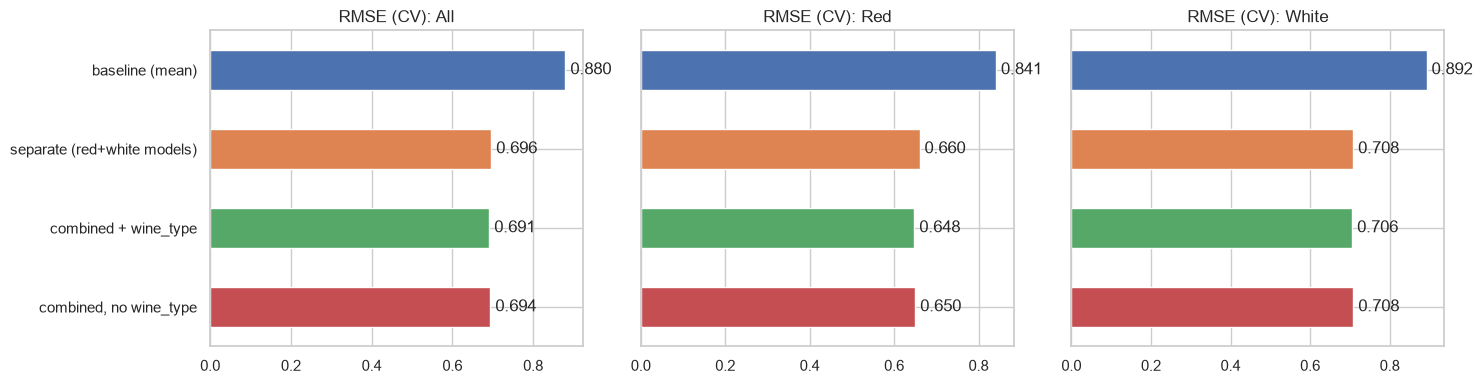

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, tbl) in zip(axes, [("All", res_all), ("Red", res_red), ("White", res_white)]):
    tbl["RMSE"].plot(kind="barh", ax=ax, color=sns.color_palette("deep")[:len(tbl)])
    ax.set_title(f"RMSE (CV): {title}"); ax.invert_yaxis()
    for i, v in enumerate(tbl["RMSE"]): ax.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

## 4. Hold-out (80/20) with the provided `evaluate_classification_metrics`

One shared stratified split; **the same test set** for all scenarios.
Separate models are trained on the train part of their own type and tested on the test part of their own type.

In [13]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED,
                                     stratify=df["wine_type"].astype(str) + "_" + df["quality"].astype(str))
tr_red,  te_red  = train_df[train_df.wine_type == 0], test_df[test_df.wine_type == 0]
tr_white, te_white = train_df[train_df.wine_type == 1], test_df[test_df.wine_type == 1]
print(len(train_df), "train /", len(test_df), "test")

svr_red   = make_svr().fit(tr_red[FEATURES],   tr_red["quality"])
svr_white = make_svr().fit(tr_white[FEATURES], tr_white["quality"])
svr_comb  = make_svr().fit(train_df[FEATURES_WITH_TYPE], train_df["quality"])
svr_nowt  = make_svr().fit(train_df[FEATURES],           train_df["quality"])

4256 train / 1064 test


--- RED model on RED test ---
Accuracy:  0.6089 (Share of exact hits)
Precision: 0.2958 (Macro)
Recall:    0.2862 (Macro)
F1-Score:  0.2858 (Macro)

--- Error distribution ---
Exact match:            60.89%
Off by 1 point:         36.53%
Gross error (>1 point): 2.58%



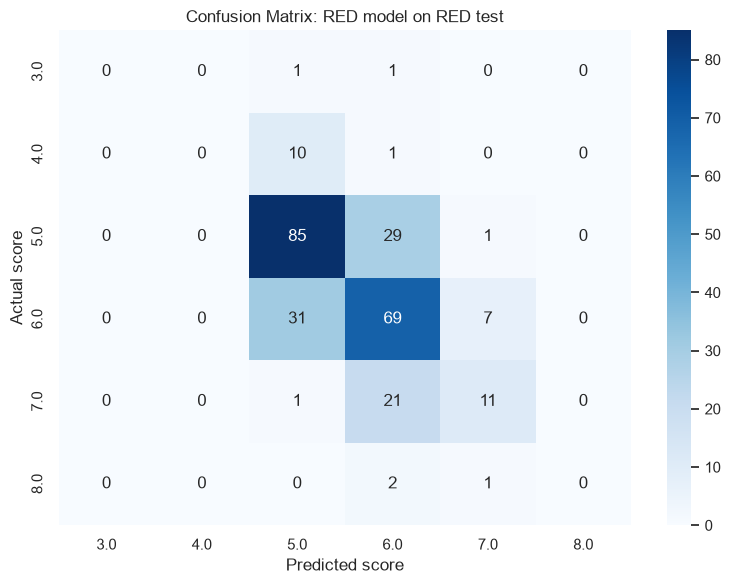

In [14]:
evaluate_classification_metrics(svr_red, te_red[FEATURES], te_red["quality"], title="RED model on RED test")

--- WHITE model on WHITE test ---
Accuracy:  0.5322 (Share of exact hits)
Precision: 0.3177 (Macro)
Recall:    0.2326 (Macro)
F1-Score:  0.2366 (Macro)

--- Error distribution ---
Exact match:            53.22%
Off by 1 point:         42.75%
Gross error (>1 point): 4.04%



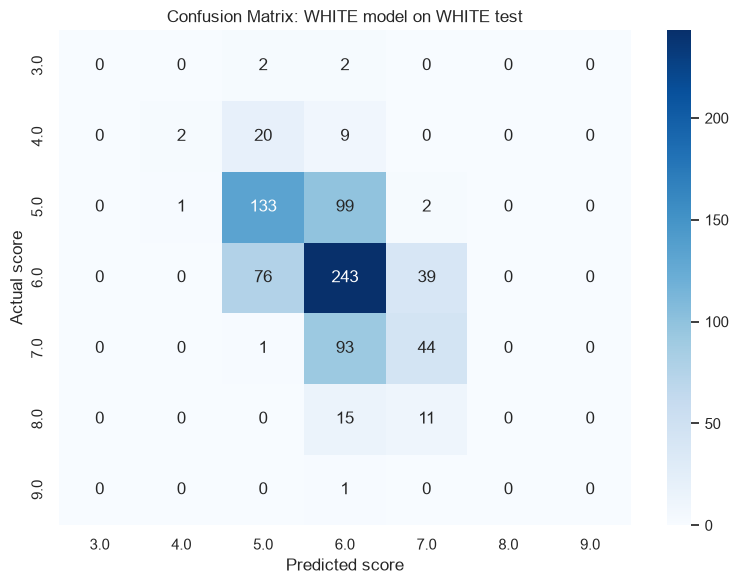

In [15]:
evaluate_classification_metrics(svr_white, te_white[FEATURES], te_white["quality"], title="WHITE model on WHITE test")

In [ ]:
evaluate_classification_metrics(svr_comb, test_df[FEATURES_WITH_TYPE], test_df["quality"], title="COMBINED + wine_type (all test)")

In [ ]:
evaluate_classification_metrics(svr_nowt, test_df[FEATURES], test_df["quality"], title="COMBINED, no wine_type (all test)")

In [11]:
# Hold-out summary by subset (identical test rows for all)
def holdout_row(model_fn, sub, feats_fn):
    return reg_metrics(sub["quality"].to_numpy(), model_fn(sub[feats_fn]))

hold = pd.DataFrame({
    "separate → red":        holdout_row(svr_red.predict,  te_red,   FEATURES),
    "combined+type → red":   holdout_row(svr_comb.predict, te_red,   FEATURES_WITH_TYPE),
    "combined no type → red":holdout_row(svr_nowt.predict, te_red,   FEATURES),
    "separate → white":        holdout_row(svr_white.predict, te_white, FEATURES),
    "combined+type → white":   holdout_row(svr_comb.predict,  te_white, FEATURES_WITH_TYPE),
    "combined no type → white":holdout_row(svr_nowt.predict,  te_white, FEATURES),
}).T.round(4)
display(hold)

,RMSE,MAE,R2,Accuracy,Within±1
separate → red,0.6455,0.4799,0.3798,0.6162,0.9779
combined+type → red,0.6482,0.4804,0.3747,0.6015,0.9705
combined no type → red,0.6484,0.4903,0.3742,0.6052,0.9779
separate → white,0.7264,0.5517,0.3348,0.5322,0.9596
combined+type → white,0.7209,0.5515,0.3447,0.5448,0.9521
combined no type → white,0.7233,0.5524,0.3405,0.5460,0.9533


## 5. How much worse does the model get without `wine_type`
Difference of the pooled model without type relative to the pooled model with type (CV, out-of-fold). Positive ΔRMSE = worse.

In [12]:
d = pd.DataFrame({
    "RMSE with type":    [reg_metrics(y[m], oof["combined + wine_type"][m])["RMSE"] for m in (np.ones(len(df), bool), is_red, is_white)],
    "RMSE without type": [reg_metrics(y[m], oof["combined, no wine_type"][m])["RMSE"] for m in (np.ones(len(df), bool), is_red, is_white)],
}, index=["all", "red", "white"])
d["ΔRMSE"] = d["RMSE without type"] - d["RMSE with type"]
d["Δ%"] = d["ΔRMSE"] / d["RMSE with type"] * 100
display(d.round(4))

,RMSE with type,RMSE without type,ΔRMSE,Δ%
all,0.7061,0.7077,0.0016,0.2249
red,0.6585,0.6598,0.0013,0.1993
white,0.7217,0.7234,0.0017,0.2322


## 6. Permutation importance (on the hold-out test set)
Computed on the test part (not on train), `n_repeats=20`. We show feature importance for the pooled model with `wine_type`, for the separate models, and for the model without the type.

,red model,white model,combined + type,combined no type
density,0.0017,0.0955,0.1120,0.1021
wine_type,NaN,NaN,0.0800,NaN
volatile acidity,0.0493,0.0369,0.0637,0.0609
alcohol,0.1084,0.0446,0.0634,0.0718
residual sugar,0.0078,0.0642,0.0632,0.0545
total sulfur dioxide,0.0293,0.0247,0.0489,0.0618
sulphates,0.0684,0.0114,0.0454,0.0455
pH,0.0140,0.0375,0.0336,0.0313
free sulfur dioxide,0.0106,0.0374,0.0328,0.0346
chlorides,0.0063,0.0112,0.0198,0.0210


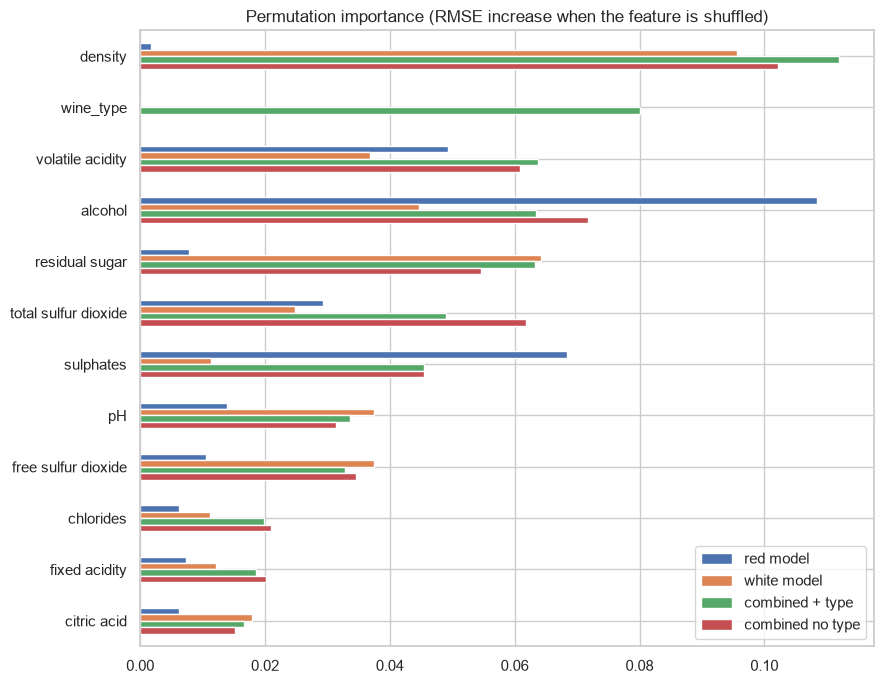

In [13]:
def perm_imp(model, X, y_):
    r = permutation_importance(model, X, y_, n_repeats=20, random_state=SEED,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
    return pd.Series(r.importances_mean, index=X.columns)

pi = pd.DataFrame({
    "red model":        perm_imp(svr_red,   te_red[FEATURES],   te_red["quality"]),
    "white model":      perm_imp(svr_white, te_white[FEATURES], te_white["quality"]),
    "combined + type":  perm_imp(svr_comb,  test_df[FEATURES_WITH_TYPE], test_df["quality"]),
    "combined no type": perm_imp(svr_nowt,  test_df[FEATURES],           test_df["quality"]),
})
pi = pi.sort_values("combined + type", ascending=False)
display(pi.round(4))

ax = pi.plot(kind="barh", figsize=(9, 7), title="Permutation importance (RMSE increase when the feature is shuffled)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## 7. Error analysis: where the model fails

,mean,count
quality,,
3,2.310,30
4,1.219,206
5,0.433,1752
6,0.375,2323
7,0.706,856
8,1.534,148
9,2.305,5


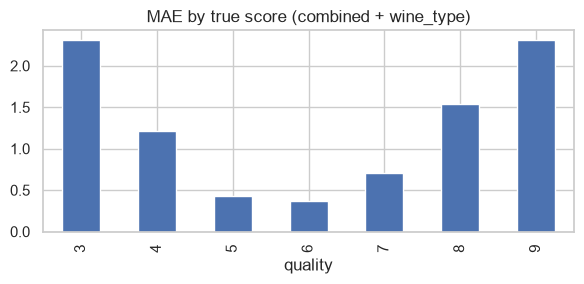

In [16]:
# MAE for each true score (CV, pooled model with wine_type)
err = pd.DataFrame({"quality": y, "abs_err": np.abs(y - oof["combined + wine_type"]),
                    "type": df["wine_type"].map({0: "red", 1: "white"})})
by_q = err.groupby("quality")["abs_err"].agg(["mean", "count"]).round(3)
display(by_q)
by_q["mean"].plot(kind="bar", figsize=(6, 3), title="MAE by true score (combined + wine_type)")
plt.tight_layout(); plt.show()

## 8. Conclusions and limitations

**Duplicates:** the EDA notebook removed 240 rows in red (15.0%) and 937 in white (19.1%); 1359 + 3961 = 5320 remain in `dataset/wine_clean.csv`.

*Run the notebook to see the exact CV results for SVR.* SVM models typically perform differently than tree-based models and heavily rely on proper scaling (which we added via `StandardScaler`). Like Random Forest, Support Vector Regressors will exhibit differences when dealing with separated vs pooled data. Observe how permutations and metrics change in your specific run!

**Limitations:**
* We tuned SVR hyperparameters (C and gamma) using GridSearchCV, which makes training much slower (nested CV during out-of-fold predictions).
* `quality` is a subjective taster score, the classes are strongly imbalanced; macro precision/recall are unstable.
* Duplicates were removed by full-row match; UCI has no wine identifier, so some "duplicates" may be different wines with identical measurements.
* Permutation importance can be computationally expensive for SVMs on larger datasets and spreads the weight between correlated features.
* The conclusions apply to this dataset and to SVR.

**Reproducibility:** `SEED = 42`, library versions are printed in the first cell; run with `jupyter nbconvert --to notebook --execute wine_svr_gridsearch_cv.ipynb`.